# Lecture 2 — Post-hoc Explainability in Machine Learning: Model Dependence, Explanation Targets, and Interpretation

### Model-specific and model-agnostic XAI methods

## Central question

> **How does access to a fitted model’s internal structure affect which post-hoc XAI methods are applicable, what quantities they explain, and how their outputs should be interpreted?**

This lecture builds on the three complementary XAI dimensions introduced in Lecture 1.

We use two recurring examples:

1. a **tabular diabetes-classification problem**;
2. a **cat image classified by a pretrained convolutional neural network (CNN)**.


> **Data:** The files used in these examples are available in the `Week2/data` folder of the course repository.

The emphasis is on identifying **what each explanation method characterises, what assumptions it relies on, and how its output should be interpreted in relation to the fitted model**.

## Learning Objectives

After this lecture, you should be able to:

- recap the three complementary dimensions introduced in Lecture 1;
- distinguish **model-specific** from **model-agnostic post-hoc** explanation methods;
- identify the level of access to model internals required by different XAI methods;
- explain **TreeExplainer, Saliency, Integrated Gradients (IG), and Grad-CAM** as model-specific approaches;
- explain **LIME, permutation importance, Partial Dependence Plots (PDPs), and Kernel SHAP** as model-agnostic approaches;
- distinguish local from global explanation independently of model dependence;
- explain why SHAP cannot be classified as simply model-specific or model-agnostic without naming the explainer;
- distinguish attribution from causal effect; and
- discuss predictive performance and explainability without assuming a universal trade-off.


## Roadmap

### Part I — Recap, explanation targets, and shared tabular setup
We briefly revisit the three XAI dimensions, clarify **what model output is being explained**, and prepare one tabular example.

### Part II — Model-specific post-hoc explainability
TreeExplainer for tree models, followed by Saliency, Integrated Gradients, and Grad-CAM for a pretrained CNN.

### Part III — Model-agnostic post-hoc explainability
LIME, permutation importance, partial dependence, and LIME Image.

### Part IV — Connecting the methods
We examine why explanation methods can disagree, how reference choices and feature dependence matter, and why SHAP spans model-specific and model-agnostic approaches.

### Part V — Predictive performance and explainability
We compare model families and use the literature to show why predictive performance and explainability should not be treated as a fixed trade-off.


# Part I. Recap

# 1. Three complementary dimensions of XAI

Lecture 1 used three dimensions to organise XAI methods. These dimensions are **complementary, not mutually exclusive**.

## Intrinsic / ante-hoc vs. post-hoc
- **Intrinsic / ante-hoc:** relevant aspects of the fitted model can be inspected directly.
- **Post-hoc:** an additional explanation method is applied after training.

## Global vs. local
- **Global:** broader model behaviour across many observations or the fitted model as a whole.
- **Local:** one prediction or a small neighbourhood.

## Model-specific vs. model-agnostic
- **Model-specific:** uses properties of a particular fitted model, model family, or architecture.
- **Model-agnostic:** can often treat the fitted model mainly as a prediction function.

### Example combinations

| Method | Intrinsic / post-hoc | Scope | Model dependence |
|---|---|---|---|
| LIME | Post-hoc | Local | Model-agnostic |
| Grad-CAM | Post-hoc | Local | Model-specific |
| Small decision tree | Intrinsic | Global + local | Model-specific interpretation |

> **This lecture focuses on model dependence within post-hoc XAI.**


## A useful refinement

Different sources organise the field differently. A common high-level distinction is:

- **interpretable models by design**;
- **post-hoc model-specific methods**;
- **post-hoc model-agnostic methods**.

Lecture 1 already covered intrinsic interpretability. Lecture 2 therefore focuses on the **post-hoc** branches rather than revisiting small trees or regression coefficients in detail.


# 2. Access to model internals and the prediction interface

Suppose a fitted model computes

$$
x \longrightarrow f(x)
$$

Two broad access regimes are relevant.

## Access to model-internal information

We may be able to inspect:

- **Tree structure** → TreeSHAP, Decision Path Analysis
- **Gradients** → Saliency Maps, Integrated Gradients, SmoothGrad
- **Feature maps and gradients** → Grad-CAM
- **Feature maps and prediction scores** → Score-CAM
- **Internal computations** → LRP, DeepLIFT

This enables **model-specific post-hoc XAI methods**.

## Access through the prediction interface

We may only be able to submit an input and observe the output.

We can still:

- **Perturb inputs** → LIME, KernelSHAP, Occlusion
- **Measure prediction or performance changes** → PDP, Permutation Feature Importance
- **Fit surrogate models** → LIME, Surrogate Decision Trees

This enables many **model-agnostic post-hoc** methods.

> Model-specific methods exploit model-internal information, whereas model-agnostic methods can often operate through the prediction interface and therefore transfer more readily across model families.

**Note:** Some methods, such as SHAP have both model-specific and model-agnostic implementations.


## 2.1 Specification of the explanation target

Before interpreting an XAI result, specify the **model output, functional quantity, or evaluation criterion that constitutes the explanation target**.

| Method | Quantity explained in this notebook |
|---|---|
| TreeExplainer | class-1 probability |
| Saliency | selected pre-softmax class score |
| Integrated Gradients | selected class score relative to a baseline |
| Grad-CAM | selected class score through internal feature maps |
| LIME | local approximation of predicted probability |
| Permutation importance | change in balanced accuracy |
| PDP | average predicted class probability |

> **Different XAI methods may characterise different mathematical quantities, even when they are applied to the same fitted model.**

Changing the explanation target can materially alter the resulting explanation.


# 3. Shared tabular example — diabetes classification

We use the provided `diabetes.csv`.

The binary target is `Outcome`, and the predictors are:

- `Pregnancies`
- `Glucose`
- `BloodPressure`
- `SkinThickness`
- `Insulin`
- `BMI`
- `DiabetesPedigreeFunction`
- `Age`

The dataset is used solely as a methodological case study for XAI; no clinical inference or diagnostic claim is intended.

## Data-quality handling

For several physiological variables, a recorded value of zero is physiologically implausible and is commonly treated as a missing-value sentinel in this dataset.

We therefore:

- retain `Pregnancies = 0` because zero previous pregnancies is a valid value;
- replace zeros with missing values for `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI`;
- split the data before fitting the imputer;
- fit the imputer only on the training partition.

The target distribution is moderately imbalanced, so we report **balanced accuracy** alongside ordinary accuracy. Balanced accuracy gives equal weight to performance on the two outcome classes.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

RANDOM_STATE = 42

data = pd.read_csv("diabetes.csv")

display(data.head())
print("Shape:", data.shape)

print("\nClass proportions:")
print(data["Outcome"].value_counts(normalize=True).sort_index())

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Shape: (768, 9)

Class proportions:
Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64


In [ ]:
zero_as_missing = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
]

X = data.drop(columns="Outcome").copy()
y = data["Outcome"].copy()

X[zero_as_missing] = X[zero_as_missing].replace(0, np.nan)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

imputer = SimpleImputer(strategy="median")

X_train_imp = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index
)

X_test_imp = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index
)

print("Training observations:", len(X_train_imp))
print("Test observations:", len(X_test_imp))

Training observations: 537
Test observations: 231


## Dataset characteristics

The dataset contains **768 observations**. About **65.1%** belong to `Outcome = 0` and **34.9%** to `Outcome = 1`.

Because the classes are not equally represented, ordinary accuracy can obscure differences in class-specific performance. This is why later model comparisons also report **balanced accuracy**.

After the stratified split, the notebook uses **537 training observations** and **231 test observations**.

# Part II — Model-Specific Post-hoc Explainability

A model-specific post-hoc method uses properties of a particular fitted model or model family **after training**.

We focus on:

- **TreeExplainer** for tree-based models;
- **Saliency**;
- **Integrated Gradients**;
- **Grad-CAM**.

These methods answer different questions and should not be interpreted as interchangeable.


# 4. TreeExplainer — model-specific for tree-based models

**SHAP (SHapley Additive exPlanations)** explains individual model predictions using feature attributions based on Shapley values. Local SHAP values can subsequently be aggregated across observations to obtain global summaries of model behaviour.

Different SHAP explainers use different computational strategies, assumptions, and levels of access to the fitted model.

**TreeExplainer** is a SHAP algorithm specialised for tree-based models. It exploits the internal structure of the fitted tree ensemble to compute Shapley-value feature attributions efficiently.

A Random Forest is difficult to inspect directly as a complete model because it combines predictions from many individual trees.

TreeExplainer therefore provides a **post-hoc** explanation while making use of model-internal information.

This gives the following combination:

> **post-hoc + local + model-specific for tree-based models**

In this example, we fit a Random Forest and explain the model's predicted probability for **class 1**.

In [ ]:
forest = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    random_state=RANDOM_STATE
)

forest.fit(X_train_imp, y_train)

forest_pred = forest.predict(X_test_imp)

print("Accuracy:",
      round(accuracy_score(y_test, forest_pred), 3))
print("Balanced accuracy:",
      round(balanced_accuracy_score(y_test, forest_pred), 3))

Accuracy: 0.74
Balanced accuracy: 0.692


## Random Forest performance before explanation

The Random Forest achieves:

- **accuracy = 0.740**
- **balanced accuracy = 0.692**

The lower balanced accuracy suggests that class-specific recall is uneven across the two outcome classes. This predictive evaluation should be considered before interpreting any explanation: XAI can describe the fitted model's behaviour, but it does not compensate for imperfect predictive performance.

In [ ]:
# In Google Colab, install once if needed:
# !pip -q install shap

try:
    import shap

    instance_idx = 7

    background = X_train_imp.sample(
        n=min(100, len(X_train_imp)),
        random_state=RANDOM_STATE
    )

    tree_explainer = shap.TreeExplainer(
        forest,
        data=background,
        feature_perturbation="interventional",
        model_output="probability"
    )

    x_one = X_test_imp.iloc[[instance_idx]]
    shap_result = tree_explainer(x_one)

    values = np.asarray(shap_result.values)
    base_values = np.asarray(shap_result.base_values)

    if values.ndim == 3:
        phi = values[0, :, 1]
        base = base_values[0, 1]
    else:
        phi = values[0]
        base = np.ravel(base_values)[0]

    prediction = forest.predict_proba(x_one)[0, 1]
    reconstructed = base + phi.sum()

    print("Reference class-1 probability:",
          round(float(base), 4))
    print("Reference + sum(SHAP):",
          round(float(reconstructed), 4))
    print("Model class-1 probability:",
          round(float(prediction), 4))

    local_shap = pd.DataFrame({
        "feature": X_test_imp.columns,
        "feature value": x_one.iloc[0].to_numpy(),
        "SHAP attribution": phi
    }).sort_values(
        "SHAP attribution",
        key=np.abs,
        ascending=False
    )

    display(local_shap)

except ImportError:
    print("Install SHAP with: !pip install shap")

predicted_class = forest.predict(x_one)[0]

print("Predicted class:", predicted_class)
print("Class probabilities:", forest.predict_proba(x_one)[0])

Reference class-1 probability: 0.3686
Reference + sum(SHAP): 0.0464
Model class-1 probability: 0.0467


,feature,feature value,SHAP attribution
5,BMI,23.900,-0.127776
1,Glucose,111.000,-0.101158
7,Age,27.000,-0.042882
3,SkinThickness,28.000,-0.028663
6,DiabetesPedigreeFunction,0.407,-0.019890
0,Pregnancies,5.000,-0.005590
4,Insulin,126.000,0.004163
2,BloodPressure,72.000,-0.000438


Predicted class: 0
Class probabilities: [0.95333333 0.04666667]


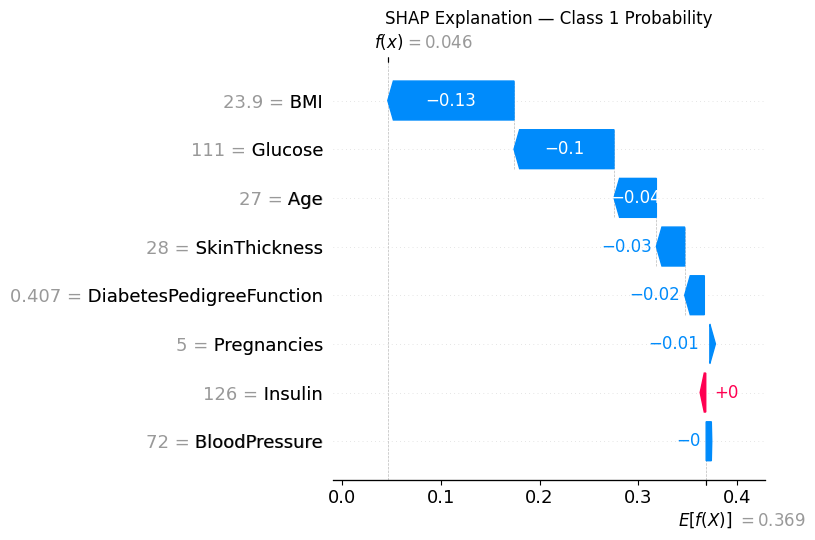

In [ ]:
# Visualize how features contribute to this prediction
shap.plots.waterfall(
    shap_result[0, :, 1],
    max_display=10,
    show=False
)

plt.title("SHAP Explanation — Class 1 Probability")
plt.tight_layout()
plt.show()


## Interpreting TreeSHAP

For the selected observation, the Random Forest assigns a class-1 probability of about **0.0467**, compared with a SHAP reference probability of about **0.369**.

The local SHAP decomposition is approximately

$$
f_1(x)
=
\phi_0
+
\sum_{j=1}^{p}\phi_j
$$

where $f_1(x)$ is the predicted probability for class 1 and $\phi_0$ is the SHAP reference output determined by the chosen background data and explainer configuration.

This notebook uses **interventional TreeSHAP** with an explicit background sample. The resulting attributions therefore depend on the selected background data and on the interventional treatment of feature dependence. Other TreeSHAP configurations, such as tree-path-dependent TreeSHAP, use a different value function and can produce different attributions.

For this observation, `BMI`, `Glucose`, and `Age` have the largest negative SHAP values, meaning that they make the strongest contributions toward moving the predicted class-1 probability below the reference value. `Insulin` has a smaller positive contribution.

The **absolute magnitude of a SHAP value** indicates the size of that feature's contribution to this prediction relative to the reference value.

The reconstructed probability (**0.0464**) is very close to the model probability (**0.0467**), as expected from the additive SHAP decomposition.

> SHAP values describe feature contributions to the prediction within the fitted model and the chosen explainer setup.

# 5. Shared image example — provided cat image

We now move from tabular data to image data.

The same image will later be used to compare:

- **model-specific** neural-network explanations;
- **model-agnostic** LIME Image.

A pretrained MobileNet model is used as the classifier.

The model was trained on ImageNet, so the prediction labels and learned visual concepts come from the ImageNet task.

> The image examples require TensorFlow. In Google Colab, install or import the listed package before running this section.


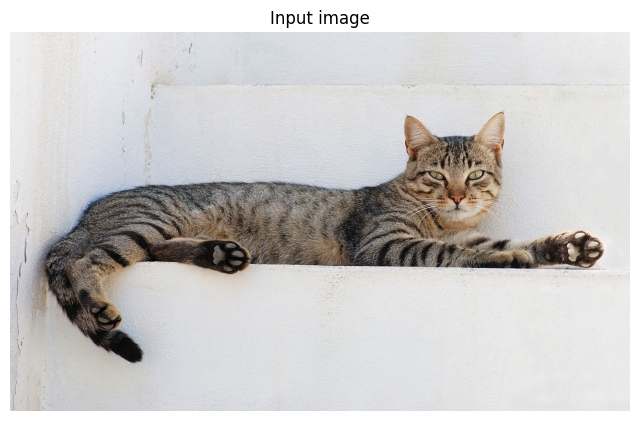

Original image size: (1200, 734)


In [ ]:
from PIL import Image

cat_img = Image.open("cat.jpg").convert("RGB")

plt.figure(figsize=(8, 5))
plt.imshow(cat_img)
plt.title("Input image")
plt.axis("off")
plt.show()

print("Original image size:", cat_img.size)

## 5.1 Saliency — local gradient sensitivity

**Saliency maps** use gradients of a selected model score with respect to the input to characterise local first-order input sensitivity.

For a selected model score $f_c(x)$, a basic saliency map uses

$$
S(x) = \nabla_x f_c(x)
$$

The gradient describes **local first-order sensitivity** of the selected score to small changes in the input.

For image data, this can be visualised at pixel level.

In the visualisation below, we display the maximum absolute gradient magnitude across the RGB channels:

$$
S_{\mathrm{vis}}(x)
=
\max_{q \in \{r,g,b\}}
\left|
\frac{\partial f_c(x)}
{\partial x_q}
\right|
$$

This removes the sign of the gradient and summarises the three colour channels into one spatial map.

A large gradient does not by itself imply:

- causal importance;
- semantic relevance;
- explanation stability;
- model correctness.

> **Visual plausibility is not sufficient evidence that a saliency map faithfully reflects the fitted model.** Raw gradients are often noisy, and explanation quality requires separate sanity or sensitivity checks.

### Related method: Guided Backpropagation

Guided Backpropagation modifies the backward pass through ReLU units to suppress negative gradients and often produces visually sharper maps. However, visual sharpness should not be confused with faithfulness: sanity-check studies have shown that Guided Backpropagation can be insensitive to model-parameter randomisation in tested CNN settings.


Top-5 ImageNet predictions:
tabby                     0.601
tiger_cat                 0.259
Egyptian_cat              0.132
tiger                     0.002
lynx                      0.002

Predicted class index: 281


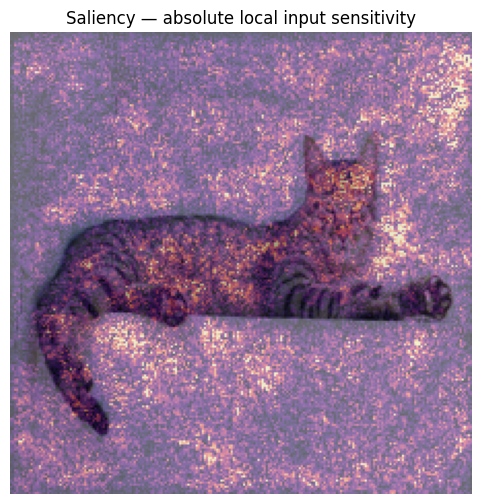

In [ ]:
# Google Colab:
!pip -q install tensorflow

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras.applications import MobileNet
from tensorflow.keras.applications.mobilenet import (
    preprocess_input,
    decode_predictions,
)

# --------------------------------------------------
# 1. Load pretrained MobileNet
# --------------------------------------------------

image_model = MobileNet(
    weights="imagenet"
)

logit_model = tf.keras.Model(
    inputs=image_model.input,
    outputs=image_model.get_layer(
        "conv_preds"
    ).output
)

# --------------------------------------------------
# 2. Load and prepare the image
# --------------------------------------------------

cat_img = Image.open(
    "cat.jpg"
).convert("RGB")

resized = cat_img.resize(
    (224, 224)
)

raw = np.asarray(
    resized,
    dtype=np.float32
)

# Standard MobileNet preprocessing
model_input = preprocess_input(
    raw[None, ...].copy()
)

# --------------------------------------------------
# 3. Obtain prediction
# --------------------------------------------------

prediction = image_model(
    model_input,
    training=False
).numpy()

top5 = decode_predictions(
    prediction,
    top=5
)[0]

print("Top-5 ImageNet predictions:")

for _, label, score in top5:
    print(
        f"{label:25s} {score:.3f}"
    )

# Explain the model's own highest-probability class
target_class = int(
    np.argmax(
        prediction[0]
    )
)

print(
    "\nPredicted class index:",
    target_class
)

# --------------------------------------------------
# 4. Compute vanilla saliency
# --------------------------------------------------

raw_tensor = tf.Variable(
    raw[None, ...],
    dtype=tf.float32
)

with tf.GradientTape() as tape:

    transformed = preprocess_input(
        raw_tensor * 1.0
    )

    # Get pre-softmax class scores
    logits_4d = logit_model(
        transformed,
        training=False
    )

    logits = tf.squeeze(
        logits_4d,
        axis=[1, 2]
    )

    target_logit = logits[
        0,
        target_class
    ]

grads = tape.gradient(
    target_logit,
    raw_tensor
)[0]

saliency = tf.reduce_max(
    tf.abs(grads),
    axis=-1
).numpy()

# --------------------------------------------------
# 5. Robust normalisation for visualisation
# --------------------------------------------------

scale = np.percentile(
    saliency,
    99
)

saliency_vis = np.clip(
    saliency / (
        scale + 1e-12
    ),
    0,
    1
)

# --------------------------------------------------
# 6. Visualise
# --------------------------------------------------

plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    resized
)

plt.imshow(
    saliency_vis,
    cmap="magma",
    alpha=0.55
)

plt.title(
    "Saliency — absolute local input sensitivity"
)

plt.axis(
    "off"
)

plt.show()

## Interpreting the saliency output

MobileNet predicts `tabby` with probability **0.601**; the next two predictions (`tiger_cat` and `Egyptian_cat`) are also feline classes.

The saliency map is visually noisy and spreads sensitivity over both the cat and background edges. This is plausible for a raw-gradient method: it measures **local pixel-level sensitivity**, not a smooth semantic object mask.

Because the visualisation uses absolute gradient magnitude, it shows **how strongly** the selected class score changes locally, but not the sign of that change.

## 5.2 Integrated Gradients — attribution relative to a baseline

**Integrated Gradients (IG)** is a baseline-relative attribution method that accumulates input gradients along a path from a reference input to the observation of interest.

Integrated Gradients accumulates gradients along a straight-line path from a baseline $x'$ to the input $x$:

$$
IG_i(x)
=
(x_i-x'_i)
\int_0^1
\frac{\partial f_c(x'+\alpha(x-x'))}{\partial x_i}
\,d\alpha
$$

For the standard formulation, Integrated Gradients satisfies a **completeness** property:

$$
\sum_i IG_i(x)
=
f_c(x)-f_c(x')
$$

This is the theoretical completeness property. In numerical implementations, the path integral is approximated using a finite number of steps, so the computed equality is only approximate.


Explained class index: 281
Output difference: 16.97924
Sum of IG attributions: 17.46236
Approximation error: 0.48311
Relative completeness error: 2.85 %


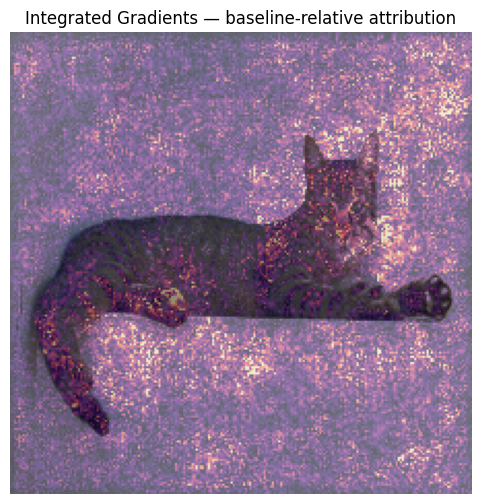

In [ ]:
# Integrated Gradients for MobileNet

def target_logit_from_raw(
    raw_batch,
    class_index
):
    """
    Return the pre-softmax score for one ImageNet class.

    Parameters
    ----------
    raw_batch : tf.Tensor
        RGB image batch in the original [0, 255] scale.

    class_index : int
        ImageNet class index to explain.
    """

    transformed = preprocess_input(
        raw_batch * 1.0
    )

    logits_4d = logit_model(
        transformed,
        training=False
    )

    # MobileNet conv_preds output:
    logits = tf.squeeze(
        logits_4d,
        axis=[1, 2]
    )

    return logits[:, class_index]


def integrated_gradients(
    raw_image,
    class_index,
    baseline,
    steps=256
):
    """
    Approximate Integrated Gradients using
    the trapezoidal rule.
    """

    alphas = tf.linspace(
        0.0,
        1.0,
        steps + 1
    )

    gradients = []

    for alpha in alphas:

        # Point along the straight-line path
        # from the baseline to the input.
        interpolated = (
            baseline
            + alpha
            * (raw_image - baseline)
        )

        with tf.GradientTape() as tape:

            tape.watch(
                interpolated
            )

            score = target_logit_from_raw(
                interpolated,
                class_index
            )[0]

        gradient = tape.gradient(
            score,
            interpolated
        )

        gradients.append(
            gradient
        )

    gradients = tf.stack(
        gradients
    )

    # Trapezoidal approximation of
    # the path integral.
    average_gradient = (
        0.5 * gradients[0]
        + tf.reduce_sum(
            gradients[1:-1],
            axis=0
        )
        + 0.5 * gradients[-1]
    ) / steps

    attributions = (
        raw_image - baseline
    ) * average_gradient

    return attributions


# --------------------------------------------------
# 1. Prepare input
# --------------------------------------------------

raw_tensor_ig = tf.convert_to_tensor(
    raw[None, ...],
    dtype=tf.float32
)


# --------------------------------------------------
# 2. Define baseline
# --------------------------------------------------

baseline = tf.ones_like(
    raw_tensor_ig
) * 127.5


# --------------------------------------------------
# 3. Select the class to explain
# --------------------------------------------------

# Explain the model's highest-probability class.
target_class_ig = int(
    np.argmax(
        prediction[0]
    )
)

print(
    "Explained class index:",
    target_class_ig
)


# --------------------------------------------------
# 4. Compute Integrated Gradients
# --------------------------------------------------

ig = integrated_gradients(
    raw_image=raw_tensor_ig,
    class_index=target_class_ig,
    baseline=baseline,
    steps=256
)[0]


# --------------------------------------------------
# 5. Completeness check
# --------------------------------------------------

input_score = target_logit_from_raw(
    raw_tensor_ig,
    target_class_ig
)[0]

baseline_score = target_logit_from_raw(
    baseline,
    target_class_ig
)[0]

output_difference = (
    input_score
    - baseline_score
)

attribution_sum = tf.reduce_sum(
    ig
)

absolute_error = tf.abs(
    output_difference
    - attribution_sum
)

relative_error = (
    absolute_error
    / (
        tf.abs(output_difference)
        + 1e-12
    )
)

print(
    "Output difference:",
    round(
        float(output_difference),
        5
    )
)

print(
    "Sum of IG attributions:",
    round(
        float(attribution_sum),
        5
    )
)

print(
    "Approximation error:",
    round(
        float(absolute_error),
        5
    )
)

print(
    "Relative completeness error:",
    round(
        float(relative_error) * 100,
        2
    ),
    "%"
)


# --------------------------------------------------
# 6. Create visualisation
# --------------------------------------------------

ig_map = tf.reduce_sum(
    tf.abs(ig),
    axis=-1
).numpy()

scale = np.percentile(
    ig_map,
    99
)

ig_vis = np.clip(
    ig_map
    / (scale + 1e-12),
    0,
    1
)


# --------------------------------------------------
# 7. Display
# --------------------------------------------------

plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    resized
)

plt.imshow(
    ig_vis,
    cmap="magma",
    alpha=0.55
)

plt.title(
    "Integrated Gradients — baseline-relative attribution"
)

plt.axis(
    "off"
)

plt.show()

## Interpreting the Integrated Gradients output

The explanation targets ImageNet class **281 (`tabby`)** and uses a neutral-grey baseline.

The numerical completeness check gives:

- output difference: **16.979**
- sum of IG attributions: **17.462**
- relative completeness error: **2.85%**

This is a reasonable numerical approximation for 256 integration steps.

The attribution remains distributed across both the cat and parts of the surrounding image. Because the displayed map uses **absolute attribution magnitude**, positive and negative contributions are combined. The map should therefore be read as **where attribution magnitude is large relative to the chosen baseline**, not as a causal or purely object-localisation map.

## 5.3 Grad-CAM — spatial localisation from internal feature maps

**Gradient-weighted Class Activation Mapping (Grad-CAM)** uses gradients of a selected class score with respect to convolutional feature maps to produce a coarse class-discriminative localisation map.

Grad-CAM combines internal convolutional feature maps with gradients of a selected class score.

For feature map $A^k$ and class score $y^c$, the channel weight is

$$
\alpha_k^c
=
\frac{1}{Z}
\sum_i\sum_j
\frac{\partial y^c}{\partial A_{ij}^k}
$$

and the Grad-CAM map is

$$
L_{\mathrm{Grad-CAM}}^c
=
\mathrm{ReLU}
\left(
\sum_k \alpha_k^c A^k
\right)
$$

The result is a **coarse class-discriminative spatial localisation map**.

Because Grad-CAM requires internal activations and gradients, it is model-specific. Its spatial resolution is limited by the selected convolutional feature map.


Explained class: tabby
Class index: 281
Predicted probability: 0.601


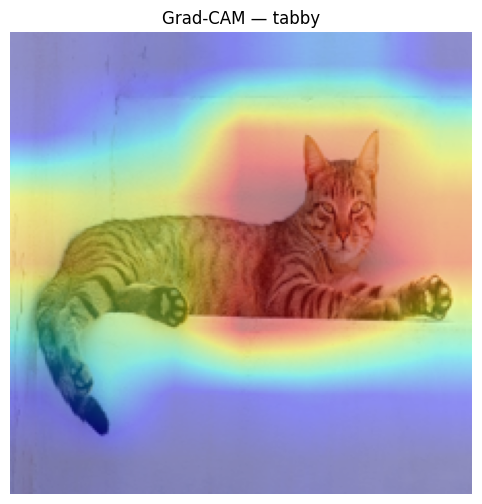

In [ ]:
# Grad-CAM for MobileNet

# --------------------------------------------------
# 1. Select a spatial convolutional layer
# --------------------------------------------------

target_layer_name = "conv_pw_13_relu"

target_layer = image_model.get_layer(
    target_layer_name
)


# --------------------------------------------------
# 2. Build a model that returns:
#    - spatial feature maps
#    - pre-softmax class scores
# --------------------------------------------------

grad_model = tf.keras.Model(
    inputs=image_model.input,
    outputs=[
        target_layer.output,
        image_model.get_layer(
            "conv_preds"
        ).output
    ]
)


# --------------------------------------------------
# 3. Prepare image
# --------------------------------------------------

transformed = preprocess_input(
    raw[None, ...].copy()
)


# --------------------------------------------------
# 4. Select class to explain
# --------------------------------------------------

# Explain the model's highest-probability class.
target_class_cam = int(
    np.argmax(
        prediction[0]
    )
)

top_prediction = decode_predictions(
    prediction,
    top=1
)[0][0]

_, class_name, probability = top_prediction

print(
    "Explained class:",
    class_name
)

print(
    "Class index:",
    target_class_cam
)

print(
    "Predicted probability:",
    round(
        float(probability),
        3
    )
)


# --------------------------------------------------
# 5. Compute gradients
# --------------------------------------------------

with tf.GradientTape() as tape:

    feature_maps, logits_4d = grad_model(
        transformed,
        training=False
    )

    # conv_preds shape
    logits = tf.squeeze(
        logits_4d,
        axis=[1, 2]
    )

    target_logit = logits[
        0,
        target_class_cam
    ]


gradients = tape.gradient(
    target_logit,
    feature_maps
)


# --------------------------------------------------
# 6. Global-average-pool gradients
# --------------------------------------------------

weights = tf.reduce_mean(
    gradients,
    axis=(1, 2)
)


# --------------------------------------------------
# 7. Weighted combination of feature maps
# --------------------------------------------------

cam = tf.reduce_sum(
    feature_maps[0]
    * weights[0][None, None, :],
    axis=-1
)

cam = tf.nn.relu(
    cam
)


# --------------------------------------------------
# 8. Normalise heatmap
# --------------------------------------------------

cam_max = tf.reduce_max(
    cam
)

if float(cam_max) > 0:
    cam = cam / cam_max


# Resize
cam = tf.image.resize(
    cam[..., None],
    (224, 224),
    method="bilinear"
)[..., 0].numpy()


# --------------------------------------------------
# 9. Display heatmap
# --------------------------------------------------

plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    resized
)

plt.imshow(
    cam,
    cmap="jet",
    alpha=0.40
)

plt.title(
    f"Grad-CAM — {class_name}"
)

plt.axis(
    "off"
)

plt.show()

## Interpreting the Grad-CAM output

Grad-CAM is computed from `conv_pw_13_relu`, a spatial feature map with substantially more localisation information than the final `1 × 1` classification layer.

For the predicted `tabby` class, the heatmap places stronger activation over much of the cat, particularly the head and central body, while also assigning some relevance to nearby context.

This is the expected qualitative behaviour of Grad-CAM: the map is **coarse and class-discriminative**, not pixel-precise. Highlighted regions should not be interpreted as causal evidence.


## Comparing the three neural-network explanations

| Method | Main quantity | Typical interpretation | Important limitation |
|---|---|---|---|
| Saliency | input gradient | local sensitivity | often visually noisy; highly local |
| Integrated Gradients | path-integrated input attribution | attribution relative to a baseline | depends on the baseline/reference |
| Grad-CAM | weighted internal feature maps | coarse class-discriminative localisation | spatial resolution is limited by the selected feature map |

These methods can produce different maps because they compute different quantities.

For this example:

- **Saliency** may remain noisy even when correctly implemented.
- **Integrated Gradients** should be interpreted relative to the neutral-grey baseline used here.
- **Grad-CAM** should be spatially coarser, but should localise meaningful image regions more clearly than a 1 × 1 output layer could.

A visually convincing heatmap is not sufficient evidence of faithfulness. Explanation quality requires separate evaluation, which is the focus of Lecture 3.


## Comparing the image explanations

The image methods should **not** be expected to produce identical maps because they compute different quantities.

| Method | Main question answered |
|---|---|
| Saliency | Where is the selected class score locally sensitive to small pixel changes? |
| Integrated Gradients | Which input regions receive large baseline-relative attribution magnitude? |
| Grad-CAM | Which coarse spatial regions are associated with positive evidence for the selected class? |
| LIME Image | Which superpixels receive positive weight in a local surrogate around this image? |

Agreement across methods can be informative, but disagreement is not automatically an error.


# Part III — Model-Agnostic Post-hoc Explainability

A model-agnostic method analyses model behaviour through inputs and outputs without requiring access to internal model structure.

It can often work mainly through

$$
x \longrightarrow f(x)
$$

This gives broader applicability across models.

However:

> **Model-agnostic does not mean assumption-free.**

Perturbation design, reference distributions, feature dependence, distance definitions, and evaluation metrics can all affect the explanation.


# 6. LIME — local surrogate explanation

**LIME (Local Interpretable Model-agnostic Explanations)** constructs an interpretable local surrogate model from perturbed samples around a selected observation in order to approximate the fitted model within that neighbourhood.

A common formulation is

$$
g^*
=
\underset{g\in G}{\operatorname{argmin}}
\;
L(f,g,\pi_x)+\Omega(g)
$$

where:

- $f$ is the fitted model;
- $g$ is the local surrogate;
- $\pi_x$ defines locality around the observation $x$;
- $\Omega(g)$ penalises surrogate complexity.

The explanation therefore depends on how the local neighbourhood is generated and weighted.


In [ ]:
# In Google Colab:
!pip -q install lime

try:
    from lime.lime_tabular import LimeTabularExplainer

    # --------------------------------------------------
    # 1. Select one test observation
    # --------------------------------------------------

    instance_idx = 7

    x_one = X_test_imp.iloc[
        instance_idx
    ]

    # --------------------------------------------------
    # 2. Create LIME explainer
    # --------------------------------------------------

    lime_explainer = LimeTabularExplainer(
        training_data=X_train_imp.to_numpy(),
        feature_names=X_train_imp.columns.tolist(),
        class_names=[
            "Outcome 0",
            "Outcome 1"
        ],
        mode="classification",
        discretize_continuous=True,
        random_state=RANDOM_STATE
    )

    # --------------------------------------------------
    # 3. Prediction wrapper
    # --------------------------------------------------

    def lime_predict(x_array):
        x_df = pd.DataFrame(
            x_array,
            columns=X_train_imp.columns
        )

        return forest.predict_proba(
            x_df
        )

    # --------------------------------------------------
    # 4. Explain the selected prediction
    # --------------------------------------------------

    lime_result = lime_explainer.explain_instance(
        data_row=x_one.to_numpy(),
        predict_fn=lime_predict,
        num_features=len(
            X_train_imp.columns
        )
    )

    # --------------------------------------------------
    # 5. Show model prediction
    # --------------------------------------------------

    class_1_probability = forest.predict_proba(
        X_test_imp.iloc[
            [instance_idx]
        ]
    )[0, 1]

    print(
        "Random Forest class-1 probability:",
        round(
            class_1_probability,
            3
        )
    )

    print(
        "\nObserved feature values:"
    )

    display(
        x_one.to_frame(
            name="value"
        )
    )

    # --------------------------------------------------
    # 6. Show local surrogate terms
    # --------------------------------------------------

    print(
        "\nLIME local surrogate terms:"
    )

    for term, weight in lime_result.as_list():
        print(
            f"{term:45s} {weight:+.4f}"
        )

    # --------------------------------------------------
    # 7. Local surrogate fidelity
    # --------------------------------------------------

    print(
        "\nLocal surrogate R²:",
        round(
            lime_result.score,
            3
        )
    )

except ImportError:
    print(
        "Install LIME with: !pip install lime"
    )

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 5.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
Random Forest class-1 probability: 0.047

Observed feature values:


,value
Pregnancies,5.000
Glucose,111.000
BloodPressure,72.000
SkinThickness,28.000
Insulin,126.000
BMI,23.900
DiabetesPedigreeFunction,0.407
Age,27.000



LIME local surrogate terms:
BMI <= 27.80                                  -0.1635
99.00 < Glucose <= 117.00                     -0.1148
122.00 < Insulin <= 126.00                    +0.0393
24.00 < Age <= 30.00                          -0.0311
3.00 < Pregnancies <= 6.00                    -0.0191
25.00 < SkinThickness <= 29.00                -0.0171
64.00 < BloodPressure <= 72.00                +0.0057
0.39 < DiabetesPedigreeFunction <= 0.65       +0.0040

Local surrogate R²: 0.205


## Interpreting the LIME result

The Random Forest assigns a class-1 probability of about **0.047** to the selected observation.

The strongest negative local surrogate terms are associated with the observed `BMI` and `Glucose` ranges, while the `Insulin` interval has a smaller positive local weight.

However, the local surrogate has **$R^2 \approx 0.205$**, which indicates a weak local approximation of the Random Forest in this neighbourhood.

> The individual LIME weights should therefore be interpreted cautiously. They are local surrogate coefficients, not causal effects and not global feature importance.

This is an important diagnostic: LIME can return an explanation even when the surrogate does not approximate the fitted model particularly well locally.


# 7. Permutation importance — global model-agnostic importance

**Permutation importance** quantifies the change in a selected predictive-performance metric when the values of one feature are randomly permuted while the fitted model remains fixed.

For a score $s$ where larger values are better, the repeated-permutation importance for feature $j$ can be written as

$$
I_j
=
s(f,D)
-
\mathbb{E}_{\pi}
\left[
s\left(f,D_{\pi(j)}\right)
\right]
$$

where $D_{\pi(j)}$ denotes the evaluation data after applying a random permutation $\pi$ to feature $j$.

In practice, the expectation is estimated by repeating the permutation several times and averaging the score decrease. In this notebook, `n_repeats=30`.

The method does not require access to internal model structure.

## Important limitations

Permutation importance depends on:

- the evaluation sample;
- the performance metric;
- feature correlation and redundancy.

A low permutation importance does **not** imply that a feature is scientifically irrelevant, and permutation importance is not a causal importance measure.

When features are correlated or redundant, shuffling one feature may underestimate its apparent importance because similar predictive information remains available in other features.


In [ ]:
perm = permutation_importance(
    forest,
    X_test_imp,
    y_test,
    scoring="balanced_accuracy",
    n_repeats=30,
    random_state=RANDOM_STATE
)

perm_df = pd.DataFrame({
    "feature": X_test_imp.columns,
    "mean decrease in balanced accuracy":
        perm.importances_mean,
    "std":
        perm.importances_std
}).sort_values(
    "mean decrease in balanced accuracy",
    ascending=False
)

display(
    perm_df.round(4)
)

,feature,mean decrease in balanced accuracy,std
1,Glucose,0.0731,0.0294
5,BMI,0.0232,0.0175
4,Insulin,0.0213,0.0171
7,Age,0.0084,0.0134
0,Pregnancies,-0.0045,0.0158
6,DiabetesPedigreeFunction,-0.0062,0.0115
2,BloodPressure,-0.0092,0.0092
3,SkinThickness,-0.0110,0.0073


## Interpreting permutation importance

Under **balanced accuracy**, `Glucose` has the largest permutation importance (**0.0731**), followed by smaller positive values for `BMI` (**0.0232**) and `Insulin` (**0.0213**).

Several features have values close to zero or slightly negative relative to the variability across repeats. These negative estimates do **not** mean “negative importance”; they indicate that shuffling those features did not reduce balanced accuracy on this evaluation sample and sometimes slightly improved it.

The result should be interpreted as **model- and metric-specific predictive reliance**, not scientific or causal importance.

# 8. Partial Dependence Plot — global average model behaviour

**Partial Dependence (PD)** estimates the average prediction of a fitted model as one selected feature is varied while the remaining predictors are marginalised over the empirical sample. A **Partial Dependence Plot (PDP)** visualises this function.

For feature $X_j$, a sample-based estimate is

$$
\widehat{PD}_j(z)
=
\frac{1}{n}
\sum_{i=1}^{n}
f\left(z, x_{-j}^{(i)}\right)
$$

where $x_{-j}^{(i)}$ denotes all other feature values for observation $i$.

This is a **global feature-effect summary of the fitted model**.

## Important limitation

If predictors are strongly dependent, PDP may evaluate feature combinations that are rare or unrealistic.

> PDP describes behaviour of the fitted prediction function under the partial-dependence calculation. It is **not evidence that the feature has a causal effect in the real world**.


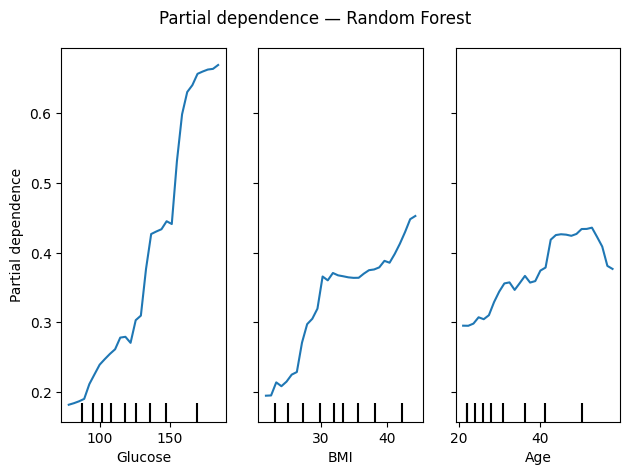

In [ ]:
PartialDependenceDisplay.from_estimator(
    forest,
    X_test_imp,
    features=[
        "Glucose",
        "BMI",
        "Age"
    ],
    grid_resolution=30
)

plt.suptitle(
    "Partial dependence — Random Forest"
)

plt.tight_layout()
plt.show()

## Interpreting the partial dependence curves

For this fitted Random Forest:

- `Glucose` shows the strongest increase in average predicted class-1 probability as its value increases;
- `BMI` also shows an overall increasing pattern, but the effect is more gradual;
- `Age` shows a weaker, non-monotonic relationship.

This complements permutation importance but answers a different question: permutation importance measures the effect of **disrupting a feature on predictive performance**, whereas PDP describes the **average shape of the model's prediction function** as a feature is varied.

These curves describe the fitted model, not real-world causal relationships.

# 9. LIME for image data — local surrogate explanations over superpixels

For image data, **LIME** applies the same local-surrogate principle using an interpretable representation based on image regions or superpixels rather than individual raw pixels.

The basic workflow is:

1. segment the image into superpixels;
2. perturb combinations of superpixels;
3. query the classifier;
4. fit a locally weighted surrogate;
5. identify superpixels with positive or negative local surrogate weights.

A key implementation detail is that the classifier's own image preprocessing should happen **inside the prediction function supplied to LIME**.

The explanation depends on the segmentation, perturbation strategy, locality weighting, and number of sampled perturbations. A visually plausible explanation is therefore not, by itself, evidence of faithfulness.


  0%|          | 0/1000 [00:00<?, ?it/s]

Explained class: tabby
Class index: 281
Predicted probability: 0.601


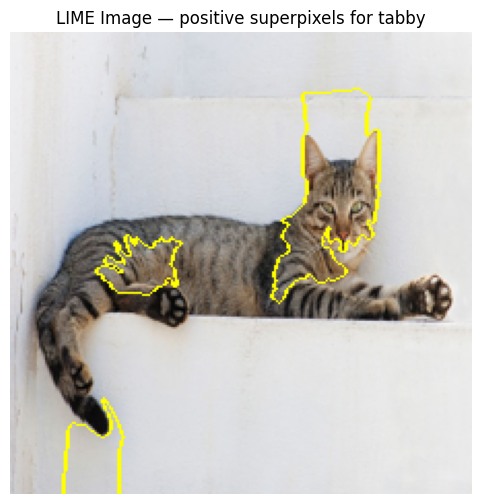

In [ ]:
# Google Colab:
# !pip -q install lime scikit-image tensorflow

try:
    from lime import lime_image
    from skimage.segmentation import (
        mark_boundaries,
        slic
    )

    # --------------------------------------------------
    # 1. Prediction function for LIME
    # --------------------------------------------------

    def mobilenet_predict(images):
        batch = np.asarray(
            images,
            dtype=np.float32
        )

        # LIME perturbs ordinary RGB image values.
        batch = preprocess_input(
            batch.copy()
        )

        return image_model.predict(
            batch,
            verbose=0
        )


    # --------------------------------------------------
    # 2. Reproducible superpixel segmentation
    # --------------------------------------------------

    def segmentation_fn(image):
        return slic(
            image,
            n_segments=60,
            compactness=10,
            sigma=1,
            start_label=0
        )


    # --------------------------------------------------
    # 3. Create LIME Image explainer
    # --------------------------------------------------

    image_explainer = lime_image.LimeImageExplainer(
        random_state=RANDOM_STATE
    )


    # --------------------------------------------------
    # 4. Explain the image prediction
    # --------------------------------------------------

    image_exp = image_explainer.explain_instance(
        image=raw.astype(np.double),
        classifier_fn=mobilenet_predict,
        top_labels=5,
        hide_color=None,
        num_samples=1000,
        segmentation_fn=segmentation_fn
    )


    # --------------------------------------------------
    # 5. Select the top predicted class
    # --------------------------------------------------

    target_label = image_exp.top_labels[0]

    top_prediction = decode_predictions(
        prediction,
        top=1
    )[0][0]

    _, class_name, probability = top_prediction

    print(
        "Explained class:",
        class_name
    )

    print(
        "Class index:",
        target_label
    )

    print(
        "Predicted probability:",
        round(
            float(probability),
            3
        )
    )


    # --------------------------------------------------
    # 6. Extract positive superpixels
    # --------------------------------------------------

    temp, mask = image_exp.get_image_and_mask(
        label=target_label,
        positive_only=True,
        num_features=5,
        hide_rest=False
    )


    # --------------------------------------------------
    # 7. Display explanation
    # --------------------------------------------------

    plt.figure(
        figsize=(8, 6)
    )

    plt.imshow(
        mark_boundaries(
            temp / 255.0,
            mask
        )
    )

    plt.title(
        f"LIME Image — positive superpixels for {class_name}"
    )

    plt.axis(
        "off"
    )

    plt.show()


except ImportError as e:
    print(
        "Optional image dependencies are not installed:",
        e
    )

except NameError:
    print(
        "Run the MobileNet image section first."
    )

## Interpreting the LIME Image result

The explained class is `tabby` with model probability **0.601**.

Several positively weighted superpixels overlap the cat, including regions around the head, upper body, and other parts of the animal. Some selected regions extend into the surrounding background.

This does not necessarily indicate an implementation problem. LIME explains a **local surrogate built from superpixel perturbations**, so contextual regions can receive weight if changing them alters the classifier output.

The highlighted regions depend on the segmentation and perturbation setup and should not be treated as a unique or causal explanation.

## LIME across modalities

The overall strategy can be reused across modalities, but the interpretable representation changes.

- **Tabular:** perturb feature values.
- **Text:** remove or mask words/tokens.
- **Image:** alter superpixels or regions.

The prediction function must itself be meaningful.

An explanation of random model outputs would not provide meaningful evidence about learned model behaviour.

# 10. Why explanation methods can yield different results

TreeSHAP, LIME, permutation importance, and PDP are **not alternative estimators of one common quantity**.

| Question | Method |
|---|---|
| How did features contribute to this prediction relative to a reference? | TreeSHAP |
| Can a simple surrogate approximate the model near this observation? | LIME |
| How much does predictive performance change when a feature is disrupted? | Permutation importance |
| How does the model prediction change on average as a feature is varied? | PDP |

> **Different methods can yield different results because they estimate different explanatory quantities under different assumptions.**

Differences between explanations should therefore be evaluated in relation to each method’s estimand, assumptions, and intended analytical question rather than by visual plausibility alone.


## 10.1 Dependence on reference and evaluation distributions

Many XAI methods are **reference- or distribution-dependent**.

- **TreeSHAP:** depends on the background/reference data and explainer configuration.
- **Integrated Gradients:** depends on the baseline.
- **LIME:** depends on the perturbation distribution, representation, and locality weighting.
- **PDP:** averages over the empirical distribution of the remaining predictors.
- **Permutation importance:** depends on the evaluation sample and scoring metric.

> These choices are constituent elements of the explanation procedure rather than incidental implementation details.


## 10.2 Effects of feature dependence and redundancy

Correlated or redundant predictors complicate many post-hoc explanations.

Methods that perturb, marginalise, or vary one feature independently can:

- create combinations of feature values that are rare or unrealistic;
- redistribute apparent importance across correlated predictors;
- make an individual feature appear less important when similar information is available elsewhere.

This issue is especially relevant for permutation importance and PDP, and it also affects how perturbation- and reference-based explanations should be interpreted.


# Part IV — SHAP as a bridge between model-specific and model-agnostic XAI

SHAP is a **family of Shapley-value-based explanation methods**. Different explainers use different computational strategies, assumptions, and levels of access to the fitted model.

## TreeExplainer

**TreeExplainer** is specialised for tree-based models.

- exploits the internal structure of tree-based models;
- computes Shapley-value feature attributions efficiently;
- is **model-specific for tree-based models**.

## KernelExplainer

**Kernel SHAP / KernelExplainer** is a model-agnostic approximation to Shapley-value feature attribution.

- operates through model queries;
- does not require access to tree structure or other model-specific internals;
- can therefore be applied across a broader range of model families.

Therefore:

> **“SHAP is model-agnostic” is too broad.**

The more precise question is:

> **Which SHAP explainer is being used, what model access does it require, and what assumptions does it make?**

# 11. Comparison of model-specific and model-agnostic approaches

| Question | Model-specific | Model-agnostic |
|---|---|---|
| Uses model internals? | Usually yes | Not necessarily |
| Prediction-only access sufficient? | Often no | Often yes |
| Can exploit architecture-specific information? | Yes | Usually no |
| Portability across model families | More limited | Broader |
| Example | Grad-CAM | LIME |
| Typical limitation | architecture/model-family dependence | perturbation/reference/approximation choices |

Neither family is universally superior.

The appropriate choice depends on:

- the fitted model;
- available access;
- data modality;
- explanation target;
- local/global scope;
- stakeholder and decision context.

# Part V — Predictive Performance and Explainability

## 12. Is there always an accuracy–explainability trade-off?

A common oversimplification is:

> “Simple models are interpretable but inaccurate; complex models are accurate but unexplainable.”

There is **no universal monotonic relationship** requiring intrinsically interpretable models to have lower predictive performance.

In some problems, greater model complexity improves predictive performance. In others, simpler or intrinsically interpretable models perform similarly or better. The relationship is **empirical, data-dependent, and task-dependent**.

Important distinctions:

- **Predictive performance** asks how well the model generalises to unseen data.
- **Intrinsic interpretability** concerns whether relevant model behaviour can be inspected directly.
- **Post-hoc explainability** concerns what additional evidence can be produced about a trained model.

Post-hoc explanation does not make a black-box model intrinsically interpretable.

### Literature perspective

**Rudin (2019)** argues that the commonly assumed accuracy–interpretability trade-off is not inevitable and that, particularly in high-stakes settings, inherently interpretable models should be seriously considered before defaulting to black boxes plus post-hoc explanations.

An empirical example is provided by **de Hond et al. (2022)**, who reported that, for their severe-asthma exacerbation prediction task, the evaluated machine-learning models did not outperform logistic regression. This does **not** imply that logistic regression is generally superior; it demonstrates that additional model complexity is not guaranteed to improve predictive performance.

> **Predictive performance and explainability should be evaluated separately rather than assumed to move in opposite directions.**


In [ ]:
candidate_models = {
    "Logistic regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Small tree (depth 3)": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(
            max_depth=3,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_features="sqrt",
            random_state=RANDOM_STATE
        ))
    ])
}

rows = []

for name, model in candidate_models.items():

    model.fit(
        X_train_raw,
        y_train
    )

    train_prediction = model.predict(
        X_train_raw
    )

    test_prediction = model.predict(
        X_test_raw
    )

    rows.append({
        "model": name,
        "train accuracy": accuracy_score(
            y_train,
            train_prediction
        ),
        "test accuracy": accuracy_score(
            y_test,
            test_prediction
        ),
        "test balanced accuracy": balanced_accuracy_score(
            y_test,
            test_prediction
        )
    })

comparison = (
    pd.DataFrame(rows)
    .set_index("model")
    .round(3)
)

display(comparison)

,train accuracy,test accuracy,test balanced accuracy
model,,,
Logistic regression,0.786,0.745,0.695
Small tree (depth 3),0.790,0.723,0.667
Random Forest,1.000,0.740,0.692


## Interpreting the model comparison

On this single train-test split:

- **Logistic regression**: test accuracy **0.745**, balanced accuracy **0.695**;
- **Small tree (depth 3)**: test accuracy **0.723**, balanced accuracy **0.667**;
- **Random Forest**: test accuracy **0.740**, balanced accuracy **0.692**.

The Random Forest reaches **1.000 training accuracy** but substantially lower test performance, producing a clear train–test gap that is consistent with overfitting on this particular split. Logistic regression has slightly higher test accuracy and balanced accuracy than the Random Forest here.

The differences are small and come from only one train-test split, so they should **not** be treated as definitive evidence that one model family is superior. Repeated cross-validation or uncertainty estimates would be needed for a stronger comparison.

The result nevertheless illustrates the following methodological point:

> **Greater model complexity does not guarantee better performance on unseen data, and there is no universal predictive-performance–explainability trade-off.**

Model selection should also consider uncertainty, error costs, subgroup behaviour where relevant, stability, and the explanation requirements of the intended use.


### Connecting this result to the literature

The result is consistent with the broader point made by **Rudin (2019)**: model complexity should not be treated as a prerequisite for strong predictive performance, especially when an interpretable alternative performs adequately.

It also mirrors the narrower empirical lesson from **de Hond et al. (2022)**: in their severe-asthma prediction setting, more complex machine-learning models did not outperform logistic regression.

These examples support a careful conclusion:

> **Model complexity is not a proxy for predictive quality, and the presence of a post-hoc explanation is not equivalent to intrinsic interpretability.**

For a rigorous model comparison, however, one should use repeated cross-validation or another appropriate uncertainty analysis rather than rely on a single split.


## 12.1 Rashomon effect

Different models can sometimes achieve similar predictive performance while relying on different patterns.

This phenomenon is commonly described as the **Rashomon effect**.

For XAI, the implication is important:

> Two similarly performing models can produce different explanations.

Therefore, an explanation should be interpreted as evidence about the **selected fitted model**, not as the unique truth about the underlying real-world problem.


# 13. Discussion activity — AI-assisted candidate screening

A technology company uses an AI model to screen job applicants.

A more complex model has somewhat stronger estimated predictive performance, but its behaviour is difficult to inspect directly. Applicants and decision makers request greater transparency, and there are concerns about possible unfair or inappropriate model behaviour.

Discuss:

1. What evidence is needed before concluding that the more complex model is meaningfully better?
2. Who are the relevant stakeholders, and what does each need explained?
3. Which questions require a global explanation?
4. Which require a local explanation?
5. When would a model-specific method be useful?
6. When would a model-agnostic method be preferable?
7. How could XAI help **investigate** possible bias?
8. What could an explanation **not prove** about fairness?
9. What if two similarly performing models produce different explanations?
10. Would your answer change if the application were movie recommendation rather than hiring?

# 14. Interpreting XAI Results

Interpretation should remain consistent with **what the explanation method actually computes**.

When interpreting an XAI result, ask:

1. **What is the explanation target?**  
   For example, a class probability, class score, prediction, or performance metric.

2. **What is the scope of the explanation?**  
   Is it local to one prediction, or aggregated across many observations?

3. **What does the explanation value represent?**  
   For SHAP, a feature attribution represents that feature's contribution to the prediction relative to the explainer's reference value.

4. **What does the sign or magnitude mean?**  
   For SHAP, positive and negative values indicate contributions that move the prediction above or below the reference value, while the **absolute magnitude** indicates the size of the contribution for that prediction.

5. **What reference or background is being used?**  
   SHAP values depend on how absent features are represented and on the chosen background or reference distribution.

6. **Are the features dependent?**  
   Correlated features can affect how attribution is distributed across features, and different SHAP formulations can lead to different interpretations.

7. **Does the explanation answer the intended question?**  
   A local attribution explains one fitted-model prediction; it should not automatically be generalised to the whole model or to real-world causal relationships.

> Interpretation should always be tied to the fitted model, the explained prediction, the explainer configuration, and the reference distribution.

# 15. Comparative map of XAI methods

| Method | Scope | Model dependence | What it produces |
|---|---|---|---|
| TreeExplainer | Local → global by aggregation | Model-specific (tree-based models) | Shapley-value feature attributions |
| Saliency | Local | Model-specific | input-gradient sensitivity |
| Integrated Gradients | Local | Model-specific | baseline-relative attribution |
| Grad-CAM | Local | Model-specific | coarse spatial localisation |
| LIME | Local | Model-agnostic | local surrogate explanation |
| Permutation importance | Global | Model-agnostic | performance-based feature importance |
| PDP | Global | Model-agnostic | average model prediction as a feature is varied |
| Kernel SHAP | Local → global by aggregation | Model-agnostic | approximate Shapley-value feature attributions |

The objective is to distinguish:

1. what model access is required;
2. what scope the explanation has;
3. what quantity or representation the method produces.

# 16. Python Exercises

Apply the XAI methods from this lecture to two different data modalities.

### Exercise 1 — Image Classification
Use **CIFAR-10** and a CNN to explore **Saliency, Integrated Gradients, and Grad-CAM**.

### Exercise 2 — Time-Series Forecasting
Use the **sunspot time series** to explore **TreeSHAP, Permutation Importance, and Partial Dependence Plots**.

# 17. Conceptual review

1. Why is TreeExplainer model-specific?
2. Why is LIME model-agnostic?
3. Why is permutation importance not Random-Forest-specific?
4. Why should PDP not automatically be interpreted causally?
5. Why is “SHAP is model-agnostic” too broad?
6. What does a saliency gradient measure?
7. Why is the Integrated Gradients baseline part of the explanation?
8. Why can a plausible heatmap still be scientifically weak?
9. Does greater model complexity guarantee better test performance?
10. What should always be specified before interpreting an attribution?

# 18. Summary

- XAI methods can be organised along several complementary dimensions.
- This lecture focused on **model dependence and the information required by post-hoc explanation methods**.
- The model output being explained must be specified explicitly.
- Model-specific methods exploit information inside a fitted model.
- Model-agnostic methods can often work primarily through input–output behaviour.
- SHAP spans both families depending on the explainer.
- Different XAI methods compute different quantities and can legitimately disagree.
- Reference choices, evaluation distributions, and feature dependence can materially affect explanations.
- Attribution does not establish causality.
- There is no universal predictive-performance–explainability trade-off.
- Model complexity is not a proxy for predictive quality.


# 19. Transition to Lecture 3

Lecture 3 asks:

> **How do we evaluate explanations?**

# Suggested Readings

- Molnar, C. (2025). *Interpretable Machine Learning: A Guide for Making Black Box Models Explainable.*  
  Particularly useful for SHAP, permutation importance, partial dependence, and practical interpretation of XAI methods.  
  https://christophm.github.io/interpretable-ml-book/

- Lundberg, S. M., & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions.* NeurIPS.  
  Foundational paper for SHAP and Shapley-value-based feature attribution.  
  https://arxiv.org/abs/1705.07874

- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). *“Why Should I Trust You?”: Explaining the Predictions of Any Classifier.* KDD.  
  Foundational paper for LIME and local surrogate explanations.  
  https://doi.org/10.1145/2939672.2939778

- Sundararajan, M., Taly, A., & Yan, Q. (2017). *Axiomatic Attribution for Deep Networks.* ICML.  
  Introduces Integrated Gradients and discusses desirable properties of attribution methods.  
  https://proceedings.mlr.press/v70/sundararajan17a.html

- Selvaraju, R. R., Cogswell, M., Das, A., et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization.* ICCV.  
  Recommended for understanding class-specific spatial localisation in CNNs.  
  https://doi.org/10.1109/ICCV.2017.74

- Adebayo, J., Gilmer, J., Muelly, M., et al. (2018). *Sanity Checks for Saliency Maps.* NeurIPS.  
  Important critical reading on why visually plausible explanations are not necessarily faithful to the model.  
  https://arxiv.org/abs/1810.03292

- Rudin, C. (2019). *Stop Explaining Black Box Machine Learning Models for High Stakes Decisions and Use Interpretable Models Instead.* Nature Machine Intelligence.  
  Useful for discussion of when post-hoc explanation may or may not be the appropriate approach.  
  https://doi.org/10.1038/s42256-019-0048-x

# References

- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). *“Why Should I Trust You?”: Explaining the Predictions of Any Classifier.* Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (KDD). https://doi.org/10.1145/2939672.2939778

- Lundberg, S. M., & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions.* Advances in Neural Information Processing Systems (NeurIPS), 30. https://arxiv.org/abs/1705.07874

- Lundberg, S. M., Erion, G., Chen, H., et al. (2020). *From Local Explanations to Global Understanding with Explainable AI for Trees.* Nature Machine Intelligence, 2, 56–67. https://doi.org/10.1038/s42256-019-0138-9

- Friedman, J. H. (2001). *Greedy Function Approximation: A Gradient Boosting Machine.* The Annals of Statistics, 29(5), 1189–1232. https://doi.org/10.1214/aos/1013203451

- Breiman, L. (2001). *Random Forests.* Machine Learning, 45, 5–32. https://doi.org/10.1023/A:1010933404324

- Simonyan, K., Vedaldi, A., & Zisserman, A. (2014). *Deep Inside Convolutional Networks: Visualising Image Classification Models and Saliency Maps.* ICLR Workshop. https://arxiv.org/abs/1312.6034

- Sundararajan, M., Taly, A., & Yan, Q. (2017). *Axiomatic Attribution for Deep Networks.* Proceedings of the 34th International Conference on Machine Learning (ICML), 70, 3319–3328. https://proceedings.mlr.press/v70/sundararajan17a.html

- Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., & Batra, D. (2017). *Grad-CAM: Visual Explanations from Deep Networks via Gradient-Based Localization.* Proceedings of the IEEE International Conference on Computer Vision (ICCV), 618–626. https://doi.org/10.1109/ICCV.2017.74

- Adebayo, J., Gilmer, J., Muelly, M., Goodfellow, I., Hardt, M., & Kim, B. (2018). *Sanity Checks for Saliency Maps.* Advances in Neural Information Processing Systems (NeurIPS), 31. https://arxiv.org/abs/1810.03292

- Kokhlikyan, N., Miglani, V., Martin, M., et al. (2020). *Captum: A Unified and Generic Model Interpretability Library for PyTorch.* arXiv:2009.07896. https://arxiv.org/abs/2009.07896

- Howard, A. G., Zhu, M., Chen, B., et al. (2017). *MobileNets: Efficient Convolutional Neural Networks for Mobile Vision Applications.* https://arxiv.org/abs/1704.04861

- Deng, J., Dong, W., Socher, R., Li, L.-J., Li, K., & Fei-Fei, L. (2009). *ImageNet: A Large-Scale Hierarchical Image Database.* Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR), 248–255. https://doi.org/10.1109/CVPR.2009.5206848

- Smith, J. W., Everhart, J. E., Dickson, W. C., Knowler, W. C., & Johannes, R. S. (1988). *Using the ADAP Learning Algorithm to Forecast the Onset of Diabetes Mellitus.* Proceedings of the Annual Symposium on Computer Applications in Medical Care, 261–265.

- Krizhevsky, A. (2009). *Learning Multiple Layers of Features from Tiny Images.* Technical Report, University of Toronto. https://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf

- National Geophysical Data Center. *Yearly Sunspot Data, 1700–2008.* Distributed through the `statsmodels` datasets collection. https://www.statsmodels.org/stable/datasets/generated/sunspots.html

- Pedregosa, F., Varoquaux, G., Gramfort, A., et al. (2011). *Scikit-learn: Machine Learning in Python.* Journal of Machine Learning Research, 12, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

- Rudin, C. (2019). *Stop Explaining Black Box Machine Learning Models for High Stakes Decisions and Use Interpretable Models Instead.* Nature Machine Intelligence, 1, 206–215. https://doi.org/10.1038/s42256-019-0048-x

- Molnar, C. (2025). *Interpretable Machine Learning: A Guide for Making Black Box Models Explainable* (3rd ed.). https://christophm.github.io/interpretable-ml-book/

- de Hond, A. A. H., Kant, I. M. J., Honkoop, P. J., et al. (2022). *Machine Learning Did Not Beat Logistic Regression in Time Series Prediction for Severe Asthma Exacerbations.* Scientific Reports, 12, Article 20363. https://doi.org/10.1038/s41598-022-24909-9


